## Trying with the approach given in [Quantile Regression with Large Language Models for Price Prediction](https://arxiv.org/pdf/2506.06657?)

In [2]:
import numpy as np
import pandas as pd
import torch
from tqdm import tqdm
import xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import train_test_split
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
torch.cuda.empty_cache()

In [18]:
# load csv
df = pd.read_csv("../clean_data/test.csv")
ids = df['sample_id'].sort_values()
# ids[ids == 279285]  # check index of id 279285
df[df['image_link'] == 'https://m.media-amazon.com/images/I/813CjSgHj0S.jpg']

,sample_id,image_link,Item Name,Description,Value,Unit
42045,286800,https://m.media-amazon.com/images/I/813CjSgHj0...,"McCormick Coriander Seed, 11-Ounce Plastic Bottle",NaN,11.0,ounce


donwload

In [5]:
import os
from pathlib import Path
from functools import partial
from urllib.parse import urlparse, unquote
from concurrent.futures import ThreadPoolExecutor, as_completed
import threading

from tqdm import tqdm
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

_thread_local = threading.local()


def _get_session() -> requests.Session:
    """Get or create a thread-local requests session with retries and pooling."""
    if getattr(_thread_local, "session", None) is None:
        session = requests.Session()
        retries = Retry(
            total=3,
            connect=3,
            read=3,
            backoff_factor=0.5,
            status_forcelist=[429, 500, 502, 503, 504],
            allowed_methods=["GET", "HEAD"],
            raise_on_status=False,
        )
        adapter = HTTPAdapter(pool_connections=100, pool_maxsize=100, max_retries=retries)
        session.mount("http://", adapter)
        session.mount("https://", adapter)
        _thread_local.session = session
    return _thread_local.session


def download_image(image_link, sample_id, savefolder):
    """
    Download a single image and save it as <sample_id>.jpg (or correct extension if found).
    """
    if not isinstance(image_link, str) or not image_link:
        return

    parsed = urlparse(image_link)
    if parsed.scheme not in ("http", "https"):
        print(f"Warning: Unsupported URL scheme - {image_link}")
        return

    # Try to infer file extension from URL (default: .jpg)
    ext = os.path.splitext(unquote(parsed.path))[-1].lower()
    if not ext or len(ext) > 5:
        ext = ".jpg"

    # Final filename = sample_id + extension
    filename = f"{sample_id}{ext}"
    image_save_path = os.path.join(savefolder, filename)

    # Skip if already downloaded and non-empty
    try:
        if os.path.exists(image_save_path) and os.path.getsize(image_save_path) > 0:
            return
    except OSError:
        pass

    session = _get_session()
    try:
        with session.get(image_link, stream=True, timeout=(5, 20)) as resp:
            resp.raise_for_status()
            os.makedirs(savefolder, exist_ok=True)
            with open(image_save_path, "wb") as f:
                for chunk in resp.iter_content(chunk_size=8192):
                    if chunk:
                        f.write(chunk)
    except Exception as ex:
        print(f"Warning: Not able to download - {image_link}\n{ex}")
        try:
            if os.path.exists(image_save_path) and os.path.getsize(image_save_path) == 0:
                os.remove(image_save_path)
        except OSError:
            pass


def download_images(image_links, sample_ids, download_folder):
    """
    Download many images concurrently using a thread pool.
    Each image is saved using its corresponding sample_id.
    
    Parameters:
    - image_links: Iterable of image URLs
    - sample_ids: Iterable of sample IDs (same length as image_links)
    - download_folder: Destination folder path
    """
    os.makedirs(download_folder, exist_ok=True)

    if len(image_links) != len(sample_ids):
        raise ValueError("image_links and sample_ids must have the same length")

    urls_and_ids = [
        (u, sid)
        for u, sid in zip(image_links, sample_ids)
        if isinstance(u, str) and u
    ]
    if not urls_and_ids:
        return

    cpu = os.cpu_count() or 8
    max_workers = min(64, max(8, cpu * 5))

    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        futures = [
            executor.submit(download_image, url, sid, download_folder)
            for url, sid in urls_and_ids
        ]
        for _ in tqdm(as_completed(futures), total=len(futures)):
            pass
    return


In [ ]:
# import pandas as pd

# df = pd.read_csv("../clean_data/test.csv")  # columns: ['sample_id', 'image_link']

# download_images(
#     image_links=df["image_link"],
#     sample_ids=df["sample_id"],
#     download_folder="../images/test_images"
# )

 56%|█████▌    | 42063/75000 [01:33<01:18, 419.55it/s]

404 Client Error: Not Found for url: https://m.media-amazon.com/images/I/813CjSgHj0S.jpg


100%|██████████| 75000/75000 [02:46<00:00, 451.68it/s]


df ready

In [19]:
df['image_path'] = "../images_resized/test_images/" + df['sample_id'].astype(str) + ".jpg"
# id = 201054
# df[df['sample_id'] == id]['Item Name'] + " " + df[df['sample_id'] == id]['Description']
# drop row with id 286800 (test)
# df = df[df['sample_id'] != 286800]
# df = df.reset_index(drop=True)
df.shape

(75000, 7)

img resize

In [ ]:
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
import os

# Function to resize a single image
def resize_image(image_id):
    try:
        img_path = f"../images/test_images/{image_id}.jpg"
        output_path = f"../images_resized/test_images/{image_id}.jpg"
        if not os.path.exists(output_path):  # Avoid reprocessing existing images
            img = Image.open(img_path)
            img = img.resize((384, 384))
            img.save(output_path)
        return f"Processed image {image_id}"
    except Exception as e:
        return f"Error processing image {image_id}: {e}"

# Skip 286800 sample id (test)
ids = ids[ids != 286800]
print("Total images to resize:", len(ids))

# Use ThreadPoolExecutor for parallel processing
with ThreadPoolExecutor(max_workers=8) as executor:  # Adjust max_workers based on your system
    results = list(executor.map(resize_image, ids))

# Print results
for result in results:
    print(result)

llm embbeding

In [ ]:
# from embedding_utils import load_model_and_tokenizer, embed_texts, save_embeddings

# # Load tokenizer and model (uses GPU if available)
# tokenizer, model, device = load_model_and_tokenizer()

# # Prepare texts from `df` if available, otherwise use demo texts
# texts = None
# try:
#     _df = df  # expect `df` from earlier notebook cell
# except NameError:
#     _df = None

# texts = None
# # concat item_name and description for embedding
# if _df is not None and "Item Name" in _df.columns and "Description" in _df.columns:
#     # make string as name: name, description: description if both are present, else only name
#     texts = []
#     for _, row in _df.iterrows():
#         name = row["Item Name"].strip()
#         desc = row["Description"].strip() if pd.notna(row["Description"]) else ""
#         if name and desc:
#             texts.append(f"name: {name}, description: {desc}")
#         elif name:
#             texts.append(f"name: {name}")

# if not texts: 
#     texts = [
#         "Red cotton t-shirt with round neck",
#         "Wireless Bluetooth headphones with noise cancellation",
#         "Lightweight running shoes size 10",
#     ]

# # write texts to a file for record
# with open("texts_for_test_embedding.txt", "w") as f:
#     for text in texts:
#         f.write(text + "\n")

# print(f"Computing embeddings for {len(texts)} texts on device {device}...")
# embs = embed_texts(texts, tokenizer, model, device, batch_size=16, normalize=True)
# print("Embeddings shape:", embs.shape)

# out_path = "mistral_test_embeddings_from_notebook.npy"
# save_embeddings(out_path, embs)
# print("Saved embeddings to", out_path)

/home/project/miniconda3/envs/romitEEG/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading checkpoint shards: 100%|██████████| 2/2 [00:00<00:00,  2.16it/s]


Computing embeddings for 75000 texts on device cuda...


Embedding texts: 100%|██████████| 4688/4688 [1:10:20<00:00,  1.11batch/s]


Embeddings shape: (75000, 4096)
Saved embeddings to mistral_test_embeddings_from_notebook.npy
Saved embeddings to mistral_test_embeddings_from_notebook.npy


vlm embedding

In [ ]:
# from VLM_embedding_utils import load_vlm, get_embeddings_from_dataset, save_embeddings
# # Load VLM model and processor (uses GPU if available)
# # clear memory
# torch.cuda.empty_cache()
# vlm_model, vlm_processor, device = load_vlm()
# # use the df to create image-text prompts and get embeddings for them 
# dataset = []
# if df is not None and "Item Name" in df.columns and "Description" in df.columns and "image_path" in df.columns:
#     for _, row in df.iterrows():
#         name = row["Item Name"].strip()
#         desc = row["Description"].strip() if pd.notna(row["Description"]) else ""
#         img_path = row["image_path"].strip() if pd.notna(row["image_path"]) else ""
#         if name and img_path:
#             prompt = f"name: {name}"
#             if desc:
#                 prompt += f", description: {desc}"
#             dataset.append({"img_path": img_path, "text": prompt})

# print(dataset[:3])
# print(f"Computing embeddings for {len(dataset)} image-text prompts on device {device}...")

# # Get embeddings for all image-text prompts
# emb = get_embeddings_from_dataset(
#     dataset,
#     vlm_processor,
#     vlm_model
# )
# emb = np.array(emb)  # Convert list of tensors to a single tensor
# print("Embedding shape:", emb.shape) # (n, dim)
# print("Embedding (first 10 values):", emb[0][:10])

# # Optionally save embeddings
# save_embeddings(emb, "image_text_prompt_embedding.npy")

/home/project/miniconda3/envs/romitEEG/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. Note that this behavior will be extended to all models in a future release.
Loading checkpoint shards: 100%|██████████| 5/5 [00:01<00:00,  3.91it/s]


cuda:0 : device for model
[{'img_path': '../images_resized/train_images/33127.jpg', 'text': 'name: La Victoria Green Taco Sauce Mild, 12 Ounce (Pack of 6)'}, {'img_path': '../images_resized/train_images/198967.jpg', 'text': 'name: Salerno Cookies, The Original Butter Cookies, 8 Ounce (Pack of 4), description: Original Butter Cookies: Classic butter cookies made with real butter | Variety Pack: Includes 4 boxes with 32 cookies total | Occasion Perfect: Delicious cookies for birthdays, weddings, anniversaries | Shareable Treats: Fun to give and enjoy with friends and family | Salerno Brand: Trusted brand of delicious butter cookies since 1925'}, {'img_path': '../images_resized/train_images/261251.jpg', 'text': 'name: Bear Creek Hearty Soup Bowl, Creamy Chicken with Rice, 1.9 Ounce (Pack of 6), description: Loaded with hearty long grain wild rice and vegetables | Full of hearty goodness | Single serve bowls | Easy to prepare mix | 0 grams trans fat'}]
Computing embeddings for 74999 image-

100%|██████████| 74999/74999 [1:06:40<00:00, 18.75it/s]


Embedding shape: torch.Size([74999, 1, 3584])
Embedding (first 10 values): tensor([[1.8115, 0.9912, 1.0557,  ..., 2.0449, 1.3467, 1.1719]],
       device='cuda:0', dtype=torch.float16)


image embeddings

In [12]:
from siglip2_utils import load_siglip2_model_and_processor, batch_embed_images, save_embeddings
import torch

# Load the SigLIP2 model and processor
model, processor = load_siglip2_model_and_processor()

# Generate embeddings for images in the DataFrame
image_paths = df['image_path'].tolist()
print(f"Generating embeddings for {len(image_paths)} images...")

# Process images in smaller batches
batch_size = 32  # Adjust batch size based on available memory
image_embeddings = []
for i in tqdm(range(0, len(image_paths), batch_size)):
    batch_paths = image_paths[i:i + batch_size]
    # print(f"Processing batch {i // batch_size + 1}/{(len(image_paths) + batch_size - 1) // batch_size}...")
    try:
        batch_embs = batch_embed_images(batch_paths, model, processor)
        image_embeddings.append(batch_embs.cpu())  # Move embeddings to CPU
        torch.cuda.empty_cache()  # Clear GPU memory
    except Exception as e:
        print(f"Error processing batch {i // batch_size + 1}: {e}")
        break

# Concatenate all batches
image_embeddings = torch.cat(image_embeddings, dim=0)
print("Image embeddings shape:", image_embeddings.shape)

# Save embeddings to a file
save_embeddings("siglip2_test_image_embeddings.npy", image_embeddings)
print("Embeddings saved to siglip2_test_image_embeddings.npy")

/home/project/miniconda3/envs/romitEEG/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading checkpoint shards: 100%|██████████| 2/2 [00:01<00:00,  1.73it/s]
/home/project/miniconda3/envs/romitEEG/lib/python3.11/site-packages/accelerate/utils/modeling.py:1614: UserWarning: The following device_map keys do not match any submodules in the model: ['logit_scale', 'logit_bias']
  warnings.warn(

/home/project/miniconda3/envs/romitEEG/lib/python3.11/site-packages/accelerate/utils/modeling.py:1614: UserWarning: The following device_map keys do not match any submodules in the model: ['logit_scale', 'logit_bias']
  warnings.warn(
Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved 

Generating embeddings for 74999 images...


100%|██████████| 2344/2344 [50:25<00:00,  1.29s/it]



Image embeddings shape: torch.Size([74999, 1536])
Embeddings saved to siglip2_test_image_embeddings.npy
Embeddings saved to siglip2_test_image_embeddings.npy


In [21]:
# Load VLM and LLM embeddings
vlm_embs = np.load("siglip2_test_image_embeddings.npy")
llm_embs = np.load("mistral_test_embeddings_from_notebook.npy")

print("vlm embeddings dim:", vlm_embs.shape)
print("llm embeddings dim:", llm_embs.shape)

# Add a zero vector for sample 286800 in VLM embeddings (test)
zero_vector = np.zeros(vlm_embs.shape[1])
if "sample_id" in df.columns:
    sample_ids = df["sample_id"].values
    idx_286800   = np.where(sample_ids == 286800)[0]
    if len(idx_286800) > 0:
        insert_idx = idx_286800[0]
        vlm_embs = np.insert(vlm_embs, insert_idx, zero_vector, axis=0)

#save vlm_embs to a file
print("Saving VLM embeddings to file...", vlm_embs.shape)
np.save("siglip2_test_image_embeddings.npy", vlm_embs)

# Concatenate VLM and LLM embeddings
concatenated_embs = np.concatenate((vlm_embs, llm_embs), axis=1)

# Create a DataFrame with the concatenated embeddings
concat_emb_df = pd.DataFrame(concatenated_embs)
concat_emb_df["price"] = df["price"].values if "price" in df.columns else np.nan

# Display the resulting DataFrame
concat_emb_df[insert_idx]

vlm embeddings dim: (75000, 1536)
llm embeddings dim: (75000, 4096)
Saving VLM embeddings to file... (75001, 1536)


ValueError: all the input array dimensions except for the concatenation axis must match exactly, but along dimension 0, the array at index 0 has size 75001 and the array at index 1 has size 75000

feature selection

In [16]:
# Load the concatenated embeddings DataFrame
X = concat_emb_df.drop(columns=["price"]).values
y = concat_emb_df["price"].values

# Train an XGBoost model to compute feature importance
model = xgb.XGBRegressor(
    objective="reg:squarederror",
    learning_rate=0.03,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    device = "cuda",
    n_estimators=500
)
model.fit(X, y)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,'cuda'
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


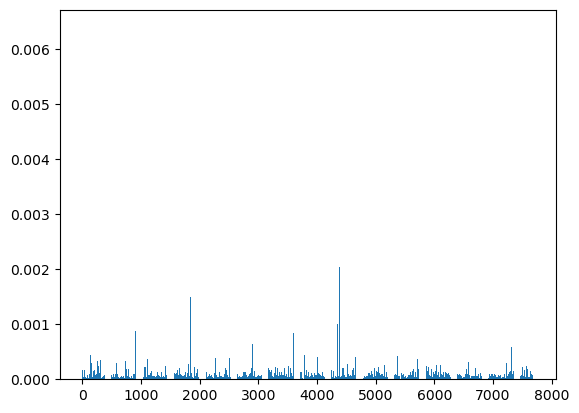

Reduced features saved to selected_features.csv with shape (75000, 2980)


In [ ]:
# Get feature importance scores
importance_scores = model.feature_importances_
plt.bar(list(range(1,7681)), importance_scores)
plt.show()

# Select features based on importance
threshold = 0.0001  # Adjust threshold based on your needs
selector = SelectFromModel(model, threshold=threshold, prefit=True)
X_selected = selector.transform(X)

# Create a new DataFrame with selected features
selected_features = selector.get_support(indices=True)
selected_feature_names = concat_emb_df.columns[selected_features]
selected_df = pd.DataFrame(X_selected, columns=selected_feature_names)
selected_df["price"] = concat_emb_df["price"]

# Save the reduced DataFrame
# selected_df.to_csv("selected_features.csv", index=False)
# print(f"Reduced features saved to selected_features.csv with shape {selected_df.shape}")

In [18]:
print("selected df shape:", selected_df.shape)

selected df shape: (75000, 2980)


In [18]:
# split df for train and val (50k and 25k samples) usking sklearn train_test_split
train_df, val_df = train_test_split(concat_emb_df, train_size=50000, test_size=25000, random_state=42)
print("Train shape:", train_df.shape)
print("Val shape:", val_df.shape)

Train shape: (50000, 5633)
Val shape: (25000, 5633)


In [6]:
def smape(y_true, y_pred):
    """Symmetric Mean Absolute Percentage Error"""
    return 100 * np.mean(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + 1e-8))

### XGBoost

In [10]:
# fit XGBRegressor model on train_df and evaluate on val_df, using embeddings as features, using SMAPE as metric
import xgboost as xgb

dtrain = xgb.DMatrix(train_df.drop(columns=["price"]), label=train_df["price"])
dval = xgb.DMatrix(val_df.drop(columns=["price"]), label=val_df["price"])

params = {
    "objective": "reg:squarederror",
    "learning_rate": 0.03,
    "max_depth": 8,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "tree_method": "gpu_hist",   
    "eval_metric": "mae",
}

num_boost_round = 2500
early_stopping_rounds = 50

# ======================
# 5. TRAINING WITH EARLY STOPPING
# ======================
print("🚀 Training XGBoost model...")
evals_result = {}

bst = xgb.train(
    params,
    dtrain,
    num_boost_round=num_boost_round,
    evals=[(dtrain, "train"), (dval, "val")],
    early_stopping_rounds=early_stopping_rounds,
    evals_result=evals_result,
    verbose_eval=50,  # show logs every 50 rounds
)

# ======================
# 6. EVALUATION
# ======================
y_pred_val = bst.predict(dval, iteration_range=(0, bst.best_iteration + 1))

val_smape = smape(val_df["price"], y_pred_val)
print(f"\n✅ Best Validation SMAPE: {val_smape:.2f} at iteration {bst.best_iteration}")

# ======================
# 7. SAVE MODEL
# ======================
bst.save_model("qwenVl_xgb_price_regressor_smape.json")
print("💾 Model saved to qwenVl_xgb_price_regressor_smape.json")

🚀 Training XGBoost model...


/home/project/miniconda3/envs/romitEEG/lib/python3.11/site-packages/xgboost/callback.py:386: UserWarning: [21:26:34] WARNING: /workspace/src/common/error_msg.cc:27: The tree method `gpu_hist` is deprecated since 2.0.0. To use GPU training, set the `device` parameter to CUDA instead.

    E.g. tree_method = "hist", device = "cuda"

  self.starting_round = model.num_boosted_rounds()


[0]	train-mae:18.36594	val-mae:18.48662
[50]	train-mae:14.55651	val-mae:15.84937
[100]	train-mae:12.84722	val-mae:15.12079
[150]	train-mae:11.69585	val-mae:14.75739
[200]	train-mae:10.79415	val-mae:14.53018
[250]	train-mae:10.05110	val-mae:14.37663
[300]	train-mae:9.38025	val-mae:14.25491
[350]	train-mae:8.78258	val-mae:14.15930
[400]	train-mae:8.25980	val-mae:14.08805
[450]	train-mae:7.78586	val-mae:14.03717
[500]	train-mae:7.32861	val-mae:13.99202
[550]	train-mae:6.90546	val-mae:13.95781
[600]	train-mae:6.49972	val-mae:13.92259
[650]	train-mae:6.11372	val-mae:13.89735
[700]	train-mae:5.74014	val-mae:13.87399
[750]	train-mae:5.38460	val-mae:13.85092
[800]	train-mae:5.06048	val-mae:13.83094
[850]	train-mae:4.75598	val-mae:13.81074
[900]	train-mae:4.46432	val-mae:13.79547
[950]	train-mae:4.18192	val-mae:13.78338
[1000]	train-mae:3.92709	val-mae:13.77150
[1050]	train-mae:3.69126	val-mae:13.76606
[1100]	train-mae:3.46493	val-mae:13.75722
[1150]	train-mae:3.27076	val-mae:13.74890
[1200]	tr

/home/project/miniconda3/envs/romitEEG/lib/python3.11/site-packages/xgboost/core.py:729: UserWarning: [21:29:17] WARNING: /workspace/src/common/error_msg.cc:27: The tree method `gpu_hist` is deprecated since 2.0.0. To use GPU training, set the `device` parameter to CUDA instead.

    E.g. tree_method = "hist", device = "cuda"

  return func(**kwargs)


💾 Model saved to qwenVl_xgb_price_regressor_smape.json


In [24]:
# Prepare data
X_train = train_df.drop(columns=["price"]).values
y_train = train_df["price"].values
X_val = val_df.drop(columns=["price"]).values
y_val = val_df["price"].values
# scaler = StandardScaler()
# X_train = scaler.fit_transform(X_train)
# X_val = scaler.transform(X_val)
train_dataset = TensorDataset(torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32))
val_dataset = TensorDataset(torch.tensor(X_val, dtype=torch.float32), torch.tensor(y_val
, dtype=torch.float32))
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)  

### DEEP WIDE MLP

Epoch 1/70, Train MAE: 12.9688, Val MAE: 12.4648, Val SMAPE: 59.6569
💾 Model saved to MistralSiglip_deep_wide_mlp_price_regressor.pth
Epoch 2/70, Train MAE: 11.9104, Val MAE: 11.8831, Val SMAPE: 54.0352
💾 Model saved to MistralSiglip_deep_wide_mlp_price_regressor.pth
Epoch 3/70, Train MAE: 11.4547, Val MAE: 11.8194, Val SMAPE: 54.1718
💾 Model saved to MistralSiglip_deep_wide_mlp_price_regressor.pth
Epoch 4/70, Train MAE: 11.1397, Val MAE: 11.6634, Val SMAPE: 52.5860
💾 Model saved to MistralSiglip_deep_wide_mlp_price_regressor.pth
Epoch 5/70, Train MAE: 10.7561, Val MAE: 11.4148, Val SMAPE: 53.3698
💾 Model saved to MistralSiglip_deep_wide_mlp_price_regressor.pth
Epoch 6/70, Train MAE: 10.4989, Val MAE: 11.4399, Val SMAPE: 54.8786
Epoch 7/70, Train MAE: 10.2236, Val MAE: 11.1938, Val SMAPE: 51.2788
💾 Model saved to MistralSiglip_deep_wide_mlp_price_regressor.pth
Epoch 8/70, Train MAE: 9.9494, Val MAE: 11.1604, Val SMAPE: 52.4378
💾 Model saved to MistralSiglip_deep_wide_mlp_price_regresso

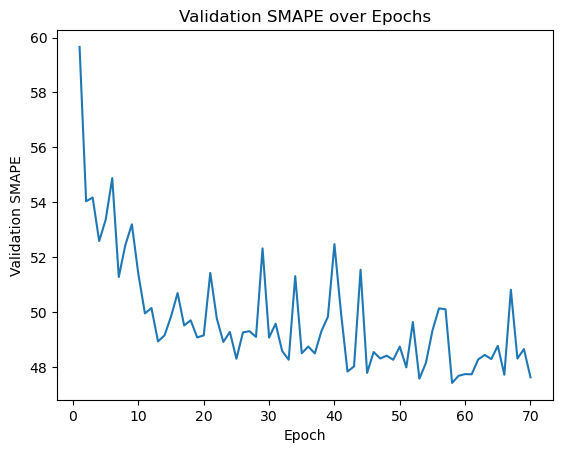

In [ ]:
# fit a simple deep wide MLP model on the same data
dropout_rate = 0.4
num_epochs = 70
class WideDeepMLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        # Deep part
        self.deep = nn.Sequential(
            nn.Linear(input_dim, 2048),
            nn.BatchNorm1d(2048),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(2048, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(512, 256),
            nn.ReLU()
        )
        # Wide part (linear projection)
        self.wide = nn.Linear(input_dim, 64)
        # Attention over deep features
        self.attn = nn.Sequential(
            nn.Linear(256, 128),
            nn.Tanh(),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )
        # Final output
        self.out = nn.Linear(256 + 64, 1)
        self.softplus = nn.Softplus()  # ensure positive output

    def forward(self, x):
        deep_feat = self.deep(x)
        wide_feat = self.wide(x)
        attn_weights = self.attn(deep_feat)
        deep_feat = deep_feat * attn_weights
        combined = torch.cat([deep_feat, wide_feat], dim=1)
        return self.softplus(self.out(combined)).squeeze(1)


device = 'cuda' if torch.cuda.is_available() else 'cpu'
input_dim = X_train.shape[1]
model = WideDeepMLP(input_dim).to(device)
criterion = nn.L1Loss()  # MAE loss
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
best_val_mae = float('inf')
smapes = []
for epoch in range(num_epochs):
    model.train()
    train_losses = []
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())
    
    model.eval()
    val_losses = []
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = criterion(y_pred, y_batch)
            val_losses.append(loss.item())
    
    avg_train_loss = np.mean(train_losses)
    avg_val_loss = np.mean(val_losses)
    # calculate SMAPE for val set
    y_val_pred = []
    with torch.no_grad():
        for X_batch, _ in val_loader:
            X_batch = X_batch.to(device)
            y_pred = model(X_batch)
            y_val_pred.extend(y_pred.cpu().numpy())
    val_smape = smape(y_val, np.array(y_val_pred))
    smapes.append(val_smape)    
    print(f"Epoch {epoch+1}/{num_epochs}, Train MAE: {avg_train_loss:.4f}, Val MAE: {avg_val_loss:.4f}, Val SMAPE: {val_smape:.4f}")

    if avg_val_loss < best_val_mae:
        best_val_mae = avg_val_loss
        torch.save(model.state_dict(), "MistralSiglip_deep_wide_mlp_price_regressor.pth")
        print("💾 Model saved to MistralSiglip_deep_wide_mlp_price_regressor.pth")

plt.plot(range(1, num_epochs+1), smapes)
plt.xlabel("Epoch")
plt.ylabel("Validation SMAPE")
plt.title("Validation SMAPE over Epochs")
plt.show()

# Two-Encoder Structure for Image and Text Embeddings

Epoch 1/70, Train MAE: 13.0110, Val MAE: 12.2587, Val SMAPE: 53.9563
💾 Model saved to MistralSiglip_two_encoder_mlp_price_regressor.pth
Epoch 2/70, Train MAE: 11.8921, Val MAE: 11.7529, Val SMAPE: 52.9966
💾 Model saved to MistralSiglip_two_encoder_mlp_price_regressor.pth
Epoch 2/70, Train MAE: 11.8921, Val MAE: 11.7529, Val SMAPE: 52.9966
💾 Model saved to MistralSiglip_two_encoder_mlp_price_regressor.pth
Epoch 3/70, Train MAE: 11.3815, Val MAE: 11.5569, Val SMAPE: 50.3738
💾 Model saved to MistralSiglip_two_encoder_mlp_price_regressor.pth
Epoch 3/70, Train MAE: 11.3815, Val MAE: 11.5569, Val SMAPE: 50.3738
💾 Model saved to MistralSiglip_two_encoder_mlp_price_regressor.pth
Epoch 4/70, Train MAE: 11.0216, Val MAE: 11.4624, Val SMAPE: 49.8396
💾 Model saved to MistralSiglip_two_encoder_mlp_price_regressor.pth
Epoch 4/70, Train MAE: 11.0216, Val MAE: 11.4624, Val SMAPE: 49.8396
💾 Model saved to MistralSiglip_two_encoder_mlp_price_regressor.pth
Epoch 5/70, Train MAE: 10.6480, Val MAE: 11.1985

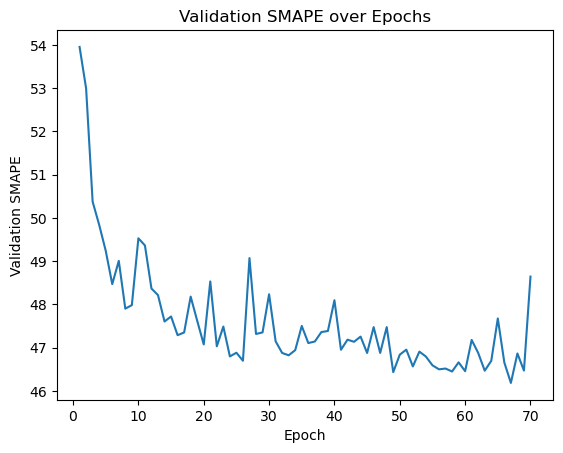

In [26]:
import torch
import torch.nn as nn

class TwoEncoderMLP(nn.Module):
    def __init__(self, image_dim, text_dim):
        super().__init__()
        dropout_rate = 0.4

        # Image encoder
        self.image_encoder = nn.Sequential(
            nn.Linear(image_dim, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(512, 256),
            nn.ReLU()
        )

        # Text encoder
        self.text_encoder = nn.Sequential(
            nn.Linear(text_dim, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(512, 256),
            nn.ReLU()
        )

        # Attention mechanism for image features
        self.image_attn = nn.Sequential(
            nn.Linear(256, 128),
            nn.Tanh(),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

        # Attention mechanism for text features
        self.text_attn = nn.Sequential(
            nn.Linear(256, 128),
            nn.Tanh(),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

        # MLP head (similar to DeepWideMLP)
        self.deep = nn.Sequential(
            nn.Linear(256 * 2, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(256, 128),
            nn.ReLU()
        )

        self.wide = nn.Linear(256 * 2, 64)

        self.attn = nn.Sequential(
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

        self.out = nn.Linear(128 + 64, 1)
        self.softplus = nn.Softplus()  # ensure positive predictions

    def forward(self, X):
        # Separate X into image_dim and text_dim
        image_embs, text_embs = X[:, :image_dim], X[:, image_dim:]

        image_feat = self.image_encoder(image_embs)
        image_attn_weights = self.image_attn(image_feat)
        image_feat = image_feat * image_attn_weights

        # Encode text features
        text_feat = self.text_encoder(text_embs)
        text_attn_weights = self.text_attn(text_feat)
        text_feat = text_feat * text_attn_weights

        # Flatten and concatenate attended features
        combined_feat = torch.cat([image_feat, text_feat], dim=1)

        # Deep and Wide MLP head
        deep_feat = self.deep(combined_feat)
        wide_feat = self.wide(combined_feat)
        attn_weights = self.attn(deep_feat)
        deep_feat = deep_feat * attn_weights
        combined = torch.cat([deep_feat, wide_feat], dim=1)
        
        return self.softplus(self.out(combined)).squeeze(1)



image_dim = 1536  # dimension for image embeddings
text_dim = 4096   # dimension for text embeddings
model = TwoEncoderMLP(image_dim, text_dim).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
best_val_mae = float('inf')
smapes = []
for epoch in range(num_epochs):
    model.train()
    train_losses = []
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())
    
    model.eval()
    val_losses = []
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = criterion(y_pred, y_batch)
            val_losses.append(loss.item())
    
    avg_train_loss = np.mean(train_losses)
    avg_val_loss = np.mean(val_losses)
    # calculate SMAPE for val set
    y_val_pred = []
    with torch.no_grad():
        for X_batch, _ in val_loader:
            X_batch = X_batch.to(device)
            y_pred = model(X_batch)
            y_val_pred.extend(y_pred.cpu().numpy())
    val_smape = smape(y_val, np.array(y_val_pred))
    smapes.append(val_smape)    
    print(f"Epoch {epoch+1}/{num_epochs}, Train MAE: {avg_train_loss:.4f}, Val MAE: {avg_val_loss:.4f}, Val SMAPE: {val_smape:.4f}")

    if avg_val_loss < best_val_mae:
        best_val_mae = avg_val_loss
        torch.save(model.state_dict(), "MistralSiglip_two_encoder_mlp_price_regressor.pth")
        print("💾 Model saved to MistralSiglip_two_encoder_mlp_price_regressor.pth")

plt.plot(range(1, num_epochs+1), smapes)
plt.xlabel("Epoch")
plt.ylabel("Validation SMAPE")
plt.title("Validation SMAPE over Epochs")
plt.show()

# Adding Cross-Attention Mechanism on Image and Text Features

In [ ]:
import torch
import torch.nn as nn

class TwoEncoderMLP(nn.Module):
    def __init__(self, image_dim, text_dim):
        super().__init__()
        dropout_rate = 0.4

        # Image encoder
        self.image_encoder = nn.Sequential(
            nn.Linear(image_dim, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(512, 256),
            nn.ReLU()
        )

        # Text encoder
        self.text_encoder = nn.Sequential(
            nn.Linear(text_dim, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(512, 256),
            nn.ReLU()
        )

        # MLP head (DeepWideMLP structure)
        self.deep = nn.Sequential(
            nn.Linear(256 * 2, 2048),
            nn.BatchNorm1d(2048),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(2048, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(512, 256),
            nn.ReLU()
        )

        self.wide = nn.Linear(256 * 2, 64)

        self.attn = nn.Sequential(
            nn.Linear(256, 128),
            nn.Tanh(),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

        self.out = nn.Linear(256 + 64, 1)
        self.softplus = nn.Softplus()  # ensure positive predictions

    def forward(self, X):
        # Separate X into image_dim and text_dim
        image_embs, text_embs = X[:, :image_dim], X[:, image_dim:]

        # Encode image features
        image_feat = self.image_encoder(image_embs)

        # Encode text features
        text_feat = self.text_encoder(text_embs)

        # Concatenate encoded features
        combined_feat = torch.cat([image_feat, text_feat], dim=1)

        # Deep and Wide MLP head
        deep_feat = self.deep(combined_feat)
        wide_feat = self.wide(combined_feat)
        attn_weights = self.attn(deep_feat)
        deep_feat = deep_feat * attn_weights
        combined = torch.cat([deep_feat, wide_feat], dim=1)

        return self.softplus(self.out(combined)).squeeze(1)

# Example usage
image_dim = 1536  # Example dimension for image embeddings
text_dim = 4096   # Example dimension for text embeddings
model = TwoEncoderMLP(image_dim, text_dim).to(device)

# Assuming `X` is the input tensor
predictions = model(X)
print("Predictions shape:", predictions.shape)